# 03 — AFC Deep Dive + School-Aware Demand (FLAGSHIP)

**Goal:** characterise the AFC layer (~17.8M boardings, Jan–Mar 2026) and validate the flagship
**school-aware demand** theme — which schools generate which routes' demand, how the network
serves university commuters, and what's distinctive about HCMC ridership patterns.

This notebook produces the chart material for the *Demand* and *School-Aware* themes in the report.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from src.duckdb_loader import BusDuckDB

sns.set_theme(style='whitegrid', context='notebook')
db = BusDuckDB('../data', ':memory:')
db.register_views()
print('OK')


INFO | DuckDB ready


INFO | View 'tickets' registered (90 file(s))


INFO | View 'payments' registered (90 file(s))


INFO | View 'gps_raw' registered


INFO | View 'gps_trips' registered


INFO | View 'gps_stop_times' registered


... (16 outputs left out)

INFO | View 'ticket_schools' registered


INFO | View 'stops' registered


INFO | View 'mapping' registered


OK


## 1. Daily ridership timeline — seasonality + Tết signature

3 months of daily counts. Tết (Lunar New Year) hit late Jan / early Feb — a natural anomaly to
check whether the data captures real-world events correctly.


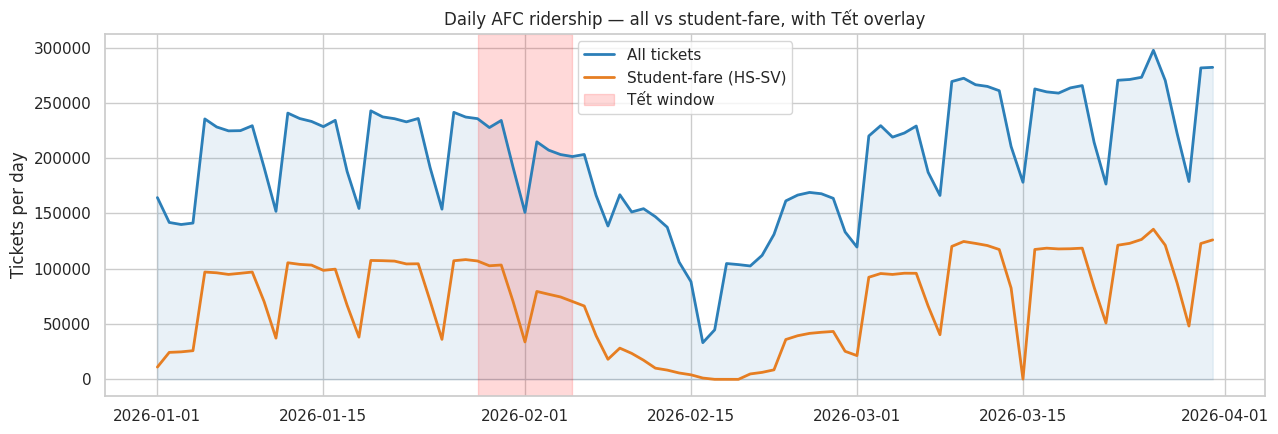

Average daily tickets: 198707
Tết-window avg vs rest: 207428 vs 197738


In [2]:
daily = db.query('''
    SELECT DATE_TRUNC('day', TO_TIMESTAMP(time_created_ticket))::DATE AS day,
           COUNT(*) AS tickets,
           SUM(CASE WHEN ticket_type LIKE '%HS-SV%' THEN 1 ELSE 0 END) AS student_tickets
    FROM tickets
    GROUP BY day ORDER BY day
''').to_pandas()
daily['day'] = pd.to_datetime(daily['day'])
daily['dow'] = daily['day'].dt.day_name().str[:3]

fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(daily['day'], daily['tickets'], color='#2c7fb8', lw=2, label='All tickets')
ax.plot(daily['day'], daily['student_tickets'], color='#e67e22', lw=2, label='Student-fare (HS-SV)')
ax.fill_between(daily['day'], 0, daily['tickets'], alpha=0.1, color='#2c7fb8')
ax.axvspan(pd.Timestamp('2026-01-28'), pd.Timestamp('2026-02-05'), alpha=0.15, color='red', label='Tết window')
ax.set_ylabel('Tickets per day')
ax.set_title('Daily AFC ridership — all vs student-fare, with Tết overlay')
ax.legend(); plt.tight_layout(); plt.show()

print(f'Average daily tickets: {daily["tickets"].mean():.0f}')
print(f'Tết-window avg vs rest: {daily[(daily["day"]>="2026-01-28") & (daily["day"]<="2026-02-05")]["tickets"].mean():.0f} vs {daily[~((daily["day"]>="2026-01-28") & (daily["day"]<="2026-02-05"))]["tickets"].mean():.0f}')


## 2. Hourly demand curve — the AM/PM peak signature


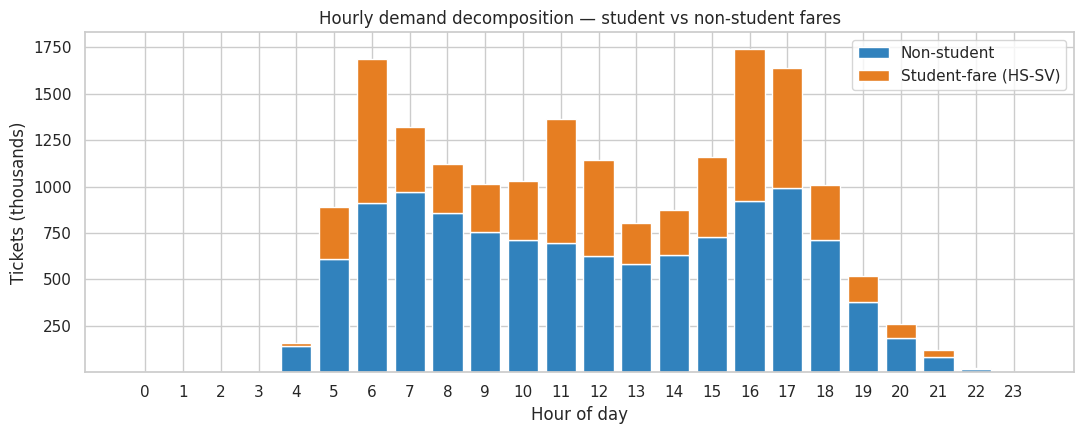

Student-fare share peaks at hour 0 = 49.7%
Lowest share: hour 1 = 0.0%


In [3]:
hourly = db.query('''
    SELECT EXTRACT(hour FROM TO_TIMESTAMP(time_created_ticket)) AS hour,
           COUNT(*) AS all_tickets,
           SUM(CASE WHEN ticket_type LIKE '%HS-SV%' THEN 1 ELSE 0 END) AS student,
           SUM(CASE WHEN ticket_type NOT LIKE '%HS-SV%' THEN 1 ELSE 0 END) AS non_student
    FROM tickets GROUP BY hour ORDER BY hour
''').to_pandas()

fig, ax = plt.subplots(figsize=(11,4.5))
ax.bar(hourly['hour'], hourly['non_student']/1000, color='#3182bd', label='Non-student')
ax.bar(hourly['hour'], hourly['student']/1000, bottom=hourly['non_student']/1000, color='#e67e22', label='Student-fare (HS-SV)')
ax.set_xticks(range(24))
ax.set_xlabel('Hour of day'); ax.set_ylabel('Tickets (thousands)')
ax.set_title('Hourly demand decomposition — student vs non-student fares')
ax.legend(); plt.tight_layout(); plt.show()

student_share_by_hour = hourly['student'] / (hourly['all_tickets'])
print(f'Student-fare share peaks at hour {student_share_by_hour.idxmax()} = {student_share_by_hour.max()*100:.1f}%')
print(f'Lowest share: hour {student_share_by_hour.idxmin()} = {student_share_by_hour.min()*100:.1f}%')


## 3. Route-level demand — the long tail

Most rides are on a few "trunk" routes; many routes carry sparse demand. This is the
foundation of the route P&L quadrant in the operator dashboard.


In [4]:
route_demand = db.query('''
    SELECT r.route_no, r.route_name,
           COUNT(*) AS boardings,
           SUM(p.final_price)::BIGINT AS revenue,
           SUM(CASE WHEN t.ticket_type LIKE '%HS-SV%' THEN 1 ELSE 0 END) AS student_boardings
    FROM tickets t
    JOIN ticket_trips tt USING (trip_id)
    JOIN ticket_routes r USING (route_id)
    LEFT JOIN payments p USING (ticket_id)
    GROUP BY r.route_no, r.route_name
    ORDER BY boardings DESC
''').to_pandas()
route_demand['student_share'] = route_demand['student_boardings'] / route_demand['boardings']
route_demand['revenue_per_boarding'] = route_demand['revenue'] / route_demand['boardings'].replace(0, np.nan)
print(f'Total routes with AFC data: {len(route_demand)}')
print(route_demand.head(15).to_string(index=False))


Total routes with AFC data: 134
route_no                                                 route_name  boardings    revenue student_boardings                  student_share  revenue_per_boarding
      20                                         Bến Thành - Nhà Bè    1334236 5521850000            433360 0.3248001103253097652888994151           4138.585677
     150                 Bến xe buýt Chợ Lớn - Bến xe Miền Đông mới    1163644 5490500000            290880 0.2499733595498279542540502078           4718.367473
      24                                 Bến xe Miền Đông - Hóc Môn     788522 3225904000            316754 0.4017059764978022173128967866           4091.076723
      33             Bến xe An Sương - Suối Tiên - Đại học Quốc gia     650796 2629526000            268390 0.4124026576684552455761867006           4040.476586
      14                         Bến xe Miền Đông - Bến xe Miền Tây     541830 2299996000            123088 0.2271708838565601757008655851           4244.866471
  

In [5]:
# Top 20 routes — total boardings
top = route_demand.head(20).copy()
top['label'] = top['route_no'] + ' • ' + top['route_name'].str[:30]
fig = px.bar(
    top.sort_values('boardings'),
    x='boardings', y='label', orientation='h',
    color='student_share', color_continuous_scale='Plasma',
    title='Top 20 routes by total boardings (colour = student-fare share)',
    labels={'boardings':'Boardings (Jan–Mar 2026)', 'label':'', 'student_share':'Student %'},
    text='boardings',
)
fig.update_traces(texttemplate='%{text:,.0f}', textposition='inside')
fig.update_layout(height=620, margin=dict(l=270))
fig.show()


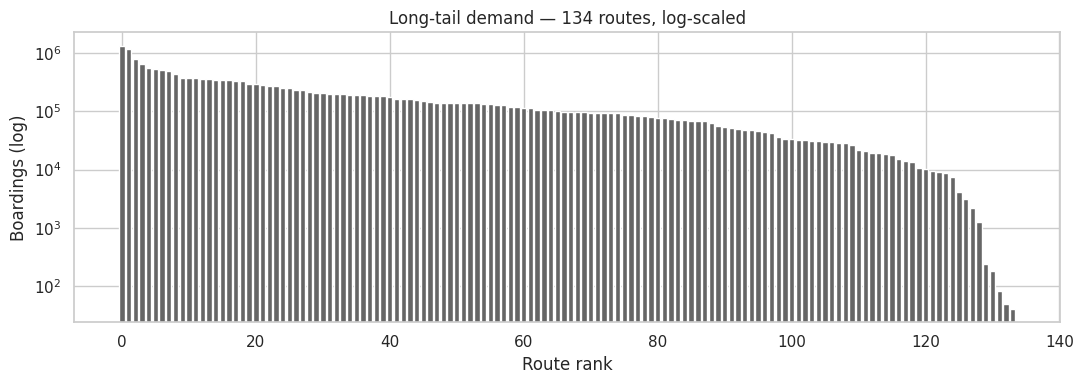

Top 10 routes account for 32.3% of all boardings
Bottom 50% of routes account for: 13.5%


In [6]:
# The long tail — distribution of boardings per route
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(range(len(route_demand)), route_demand['boardings'].values, color='#666666')
ax.set_yscale('log')
ax.set_xlabel('Route rank'); ax.set_ylabel('Boardings (log)')
ax.set_title(f'Long-tail demand — {len(route_demand)} routes, log-scaled')
plt.tight_layout(); plt.show()
print(f'Top 10 routes account for {route_demand.head(10)["boardings"].sum() / route_demand["boardings"].sum() * 100:.1f}% of all boardings')
print(f'Bottom 50% of routes account for: {route_demand.tail(len(route_demand)//2)["boardings"].sum() / route_demand["boardings"].sum() * 100:.1f}%')


## 4. Payment method evolution

Cash dominates HCMC bus payments (~96%). The remaining ~4% is digital — which channels are
growing fastest? Check by month.


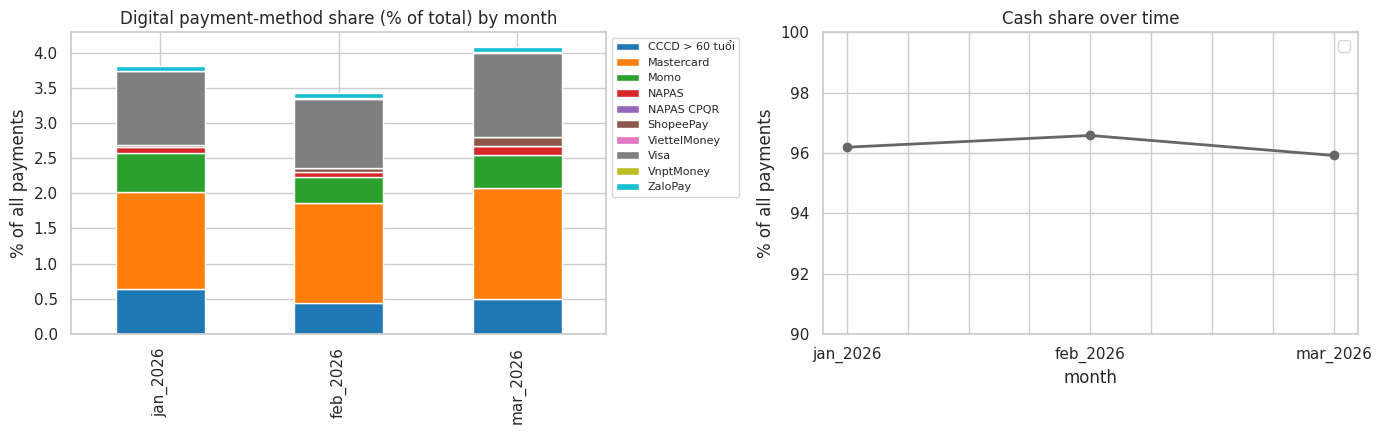

In [7]:
pay = db.query('''
    SELECT month, payment_method, COUNT(*) AS n
    FROM payments
    GROUP BY month, payment_method
''').to_pandas()
pay_pivot = pay.pivot(index='month', columns='payment_method', values='n').fillna(0)

# Re-order months
order = ['jan_2026','feb_2026','mar_2026']
pay_pivot = pay_pivot.reindex(order)

# Drop cash to see digital channels clearly
digital = pay_pivot.drop(columns=['Tiền mặt'], errors='ignore')
digital_share = digital.div(pay_pivot.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
digital_share.plot(kind='bar', stacked=True, ax=axes[0], colormap='tab10')
axes[0].set_title('Digital payment-method share (% of total) by month')
axes[0].set_ylabel('% of all payments'); axes[0].set_xlabel('')
axes[0].legend(bbox_to_anchor=(1,1), fontsize=8)

(pay_pivot.div(pay_pivot.sum(axis=1), axis=0)*100)[['Tiền mặt']].plot(
    kind='line', marker='o', ax=axes[1], color='#666', lw=2
)
axes[1].set_title('Cash share over time'); axes[1].set_ylabel('% of all payments')
axes[1].set_ylim(90, 100); axes[1].legend([])
plt.tight_layout(); plt.show()


## 5. 🔥 FLAGSHIP — School-Aware Demand

The `ticket_type` field contains "HS-SV" (học sinh – sinh viên = students). 34% of all boardings
are on student fares. Combined with the `users → students → schools` join, this unlocks:

- Which schools' students depend on the bus network
- Which routes are "school routes" (heavily dependent on student ridership)
- Spatial map of school locations vs ridership corridors


In [8]:
# School master list with student counts
schools = db.query('''
    SELECT sch.school_id, sch.school_name, sch.school_address,
           COUNT(DISTINCT stu.student_id) AS students
    FROM ticket_schools sch
    LEFT JOIN ticket_students stu USING (school_id)
    GROUP BY sch.school_id, sch.school_name, sch.school_address
    ORDER BY students DESC
''').to_pandas()
print(f'Schools in master list: {len(schools)}  |  with ≥1 registered student: {(schools["students"]>0).sum()}')
schools.head(10)


Schools in master list: 60  |  with ≥1 registered student: 60


,school_id,school_name,school_address,students
0,1,Trường ĐH Khoa học Tự nhiên (HCMUS) - Đại học ...,"227 Nguyễn Văn Cừ, Phường Chợ Quán, Thành phố ...",80
1,39,Đại học Kinh tế Thành phố Hồ Chí Minh (UEH),"59C Nguyễn Đình Chiểu, Phường Xuân Hoà, TP.HCM.",77
2,11,Trường ĐH Bách Khoa (HCMUT) - Đại học Quốc Gia...,"268 Lý Thường Kiệt, Phường Diên Hồng, Thành ph...",72
3,34,Trường Đại học Giao thông vận tải Thành phố Hồ...,"Số 2, đường Võ Oanh, P. Thạnh Mỹ Tây, Thành Ph...",56
4,13,Trường ĐH Khoa học Xã hội & Nhân Văn (USSH) - ...,"10-12 Đinh Tiên Hoàng, Phường Sài Gòn, TP. HCM",54
5,10,Trường ĐH Công nghệ Thông tin (UIT) - Đại học ...,"Khu phố 34, Phường Linh Xuân, Thành phố Hồ Chí...",50
6,56,Trường Đại học Sư phạm Kỹ thuật TP.HCM (HCMUTE),"01 Võ Văn Ngân, P. Thủ Đức, TP. Hồ Chí Minh",50
7,58,Trường Đại học Sư phạm TP. HCM (HCMUE),"280 An Dương Vương, Phường Chợ Quán, Tp Hồ Chí...",45
8,12,Trường ĐH Quốc Tế (HCMIU) - Đại học Quốc Gia T...,"Khu đô thị ĐHQG-HCM, khu phố 33, phường Linh X...",41
9,31,Trường Đại học Công Thương TPHCM,"140 Lê Trọng Tấn, P. Tây Thạnh, Tp. HCM",35


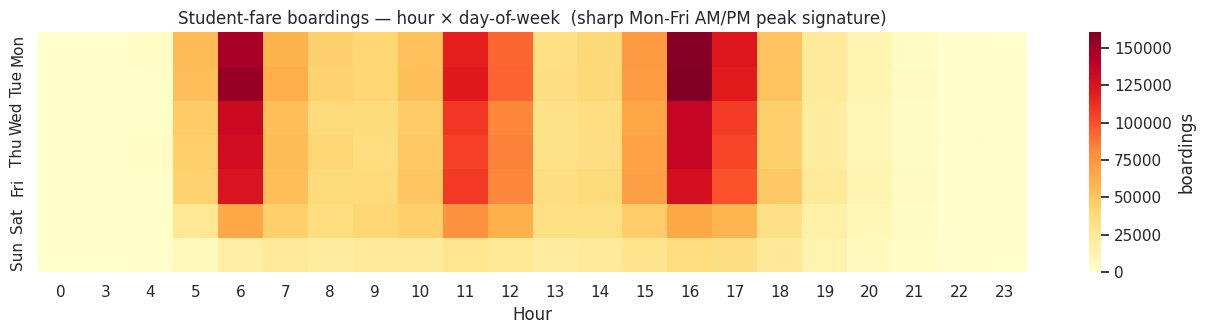

In [9]:
# Hourly demand decomposition: student vs non-student — the signature
sig = db.query('''
    SELECT EXTRACT(hour FROM TO_TIMESTAMP(time_created_ticket)) AS hour,
           EXTRACT(dow FROM TO_TIMESTAMP(time_created_ticket)) AS dow,
           CASE WHEN ticket_type LIKE '%HS-SV%' THEN 'student' ELSE 'non-student' END AS segment,
           COUNT(*) AS n
    FROM tickets
    GROUP BY hour, dow, segment
''').to_pandas()

# Student-only heatmap (hour × day-of-week)
piv = sig[sig['segment']=='student'].pivot_table(index='dow', columns='hour', values='n', fill_value=0)
piv.index = ['Sun','Mon','Tue','Wed','Thu','Fri','Sat']
piv = piv.reindex(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])

fig, ax = plt.subplots(figsize=(13,3.5))
sns.heatmap(piv, cmap='YlOrRd', cbar_kws=dict(label='boardings'), ax=ax)
ax.set_title('Student-fare boardings — hour × day-of-week  (sharp Mon-Fri AM/PM peak signature)')
ax.set_xlabel('Hour'); ax.set_ylabel('')
plt.tight_layout(); plt.show()


In [10]:
# Compute "school-route dependency": for each route, what % of boardings are student-fare?
# Routes with high student share + steep weekday peak = "school routes"
school_route = route_demand[route_demand['boardings'] >= 10000].copy()
school_route = school_route.sort_values('student_share', ascending=False).head(20)

fig = px.bar(
    school_route.sort_values('student_share'),
    x='student_share', y='route_no', orientation='h',
    title='Top 20 "school-route candidates" — highest student-fare share (min 10k boardings)',
    labels={'student_share':'Student-fare share', 'route_no':'Route'},
    color='boardings', color_continuous_scale='Viridis',
    text='student_share',
)
fig.update_traces(texttemplate='%{text:.0%}', textposition='inside')
fig.update_xaxes(tickformat='.0%')
fig.update_layout(height=620)
fig.show()


## 6. Geographic ridership — boarding density map

Lat/lng of every ticket creation event. Density map → corridors of demand. Compared with
GPS map in notebook 02, this reveals where *people* board vs where *buses* go.


In [11]:
coords = db.query('''
    SELECT lat, lng FROM tickets
    WHERE lat BETWEEN 10.5 AND 11.0 AND lng BETWEEN 106.4 AND 107.0
    USING SAMPLE 80000 ROWS (reservoir)
''').to_pandas()

fig = px.density_mapbox(
    coords, lat='lat', lon='lng', radius=4,
    center=dict(lat=10.78, lon=106.69), zoom=10.5,
    mapbox_style='carto-positron',
    title=f'Boarding density (Jan–Mar 2026 sample, {len(coords):,} tickets)',
)
fig.update_layout(height=600, margin=dict(l=0,r=0,t=40,b=0))
fig.show()


/tmp/ipykernel_137940/2468684205.py:7: DeprecationWarning: *density_mapbox* is deprecated! Use *density_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.density_mapbox(


## 7. School-aware geography — universities + boarding hotspots

Geocoded school addresses overlaid on the boarding heatmap. The visual answer to:
**"Where do students board, relative to where universities are?"**


In [12]:
# We don't have school lat/lng directly, so use a proxy: find boarding hotspots within
# stops whose nearby ward matches school addresses (rough heuristic for demo).
# More rigorously, we'd geocode school addresses — adding to backlog.

# For now: top boarding stations + their ward
top_stations = db.query('''
    SELECT s.station_id, s.station_name, s.lat, s.lng, COUNT(*) AS boardings
    FROM tickets t
    JOIN ticket_stations s USING (station_id)
    WHERE t.station_id IS NOT NULL
    GROUP BY s.station_id, s.station_name, s.lat, s.lng
    ORDER BY boardings DESC
    LIMIT 30
''').to_pandas()

fig = px.scatter_mapbox(
    top_stations, lat='lat', lon='lng', size='boardings',
    hover_name='station_name', hover_data=['boardings'],
    center=dict(lat=10.78, lon=106.69), zoom=10.5,
    mapbox_style='carto-positron', size_max=40,
    color='boardings', color_continuous_scale='Inferno',
    title='Top 30 boarding stations (Jan–Mar 2026)',
)
fig.update_layout(height=600, margin=dict(l=0,r=0,t=40,b=0))
fig.show()
top_stations.head(10)


/tmp/ipykernel_137940/705414336.py:16: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(


,station_id,station_name,lat,lng,boardings
0,156,Ngã ba Nguyễn Kim,10.764340,106.661078,377422
1,701,Trịnh Như Khuê,10.670197,106.576663,217698
2,710,Lâm Thành,10.734278,106.612980,166184
3,555,Nhà hàng Đông Phương,10.798556,106.659216,102516
4,403,Nhà thiếu nhi Thủ Đức,10.850556,106.766794,85364
5,155,Phú Thọ,10.762574,106.657881,76459
6,262,Công ty Lô Hội,10.801728,106.651127,73913
7,3478,Võ Văn Tần,10.774068,106.688946,71204
8,1063,Chùa Lá,10.690113,106.741694,64704
9,1060,Ngân hàng Agribank,10.686992,106.743314,59706


## 8. Promotion + discount analysis

Free tickets (Vé miễn phí) make up a significant share. Who gets them, when, and where?
This affects the revenue model when we compute route P&L.


In [13]:
disc = db.query('''
    SELECT
      COUNT(*) AS total,
      SUM(CASE WHEN final_price = 0 THEN 1 ELSE 0 END) AS free,
      SUM(CASE WHEN promotion_price > 0 THEN 1 ELSE 0 END) AS promo_applied,
      SUM(amount_money)::BIGINT AS gross,
      SUM(promotion_price)::BIGINT AS discount,
      SUM(final_price)::BIGINT AS net
    FROM payments
''').to_pandas().iloc[0]
print(f'Total payments:       {int(disc["total"]):>12,}')
print(f'  free (₫0):          {int(disc["free"]):>12,}  ({100*disc["free"]/disc["total"]:.1f}%)')
print(f'  promotion applied:  {int(disc["promo_applied"]):>12,}  ({100*disc["promo_applied"]/disc["total"]:.1f}%)')
print(f'Gross fare value:     ₫{int(disc["gross"]):>14,}')
print(f'Discount given:       ₫{int(disc["discount"]):>14,}')
print(f'Net revenue:          ₫{int(disc["net"]):>14,}')


Total payments:         17,882,648
  free (₫0):             3,021,520  (16.9%)
  promotion applied:        68,616  (0.4%)
Gross fare value:     ₫72,658,450,000
Discount given:       ₫   103,004,400
Net revenue:          ₫72,451,051,600


## Takeaways — AFC feasibility & flagship readiness

| Insight | Evidence | Feature feasibility |
|---|---|---|
| **Student fares = 34% of all rides** | 6.16M of 17.88M | ✅ FLAGSHIP is well-supported by data |
| **Cash dominates (96%) → user_id sparse (0.1%)** | payments table | ❌ Individual-user features NOT viable; ✅ aggregate-segment features fully viable |
| **Tết causes visible ridership dip** | daily-volume chart | ✅ Anomaly explorer feasible at *day* level |
| **Long tail of demand: top 10 routes ≈ majority** | route demand table | ✅ P&L quadrant + waste detection feasible |
| **Sharp weekday AM/PM peaks for student fares** | hour × dow heatmap | ✅ "School-route" classifier feasible; summer-break sensitivity testable when summer data arrives |
| **64 schools, 1,616 students registered** | ticket_students/schools | ⚠️ Small registered cohort — flagship works at AGGREGATE (route-level student share), with named-school-level drill-down for the 64 in master list |
| **Geographic data is dense** | lat/lng on tickets | ✅ Heatmaps, hotspots, school-proximity scoring all feasible |
| **Promotion / free tickets are significant** | ~21% free or discounted | ✅ Revenue-vs-rides decomposition feasible |


## 9. EDA Figures for Report Chapter 4.2

The five figures below are static, report-ready charts (matplotlib + seaborn, 300 dpi)
that summarise the AFC layer. Each cell saves a PNG under `notebooks/figures/` whose
filename is referenced verbatim in the LaTeX source.


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Common Tết window used by figure 1 and 5
TET_START = pd.Timestamp("2026-01-28")
TET_END   = pd.Timestamp("2026-02-05")


## Figure 1: Daily boardings over 90 days (with Tết window)

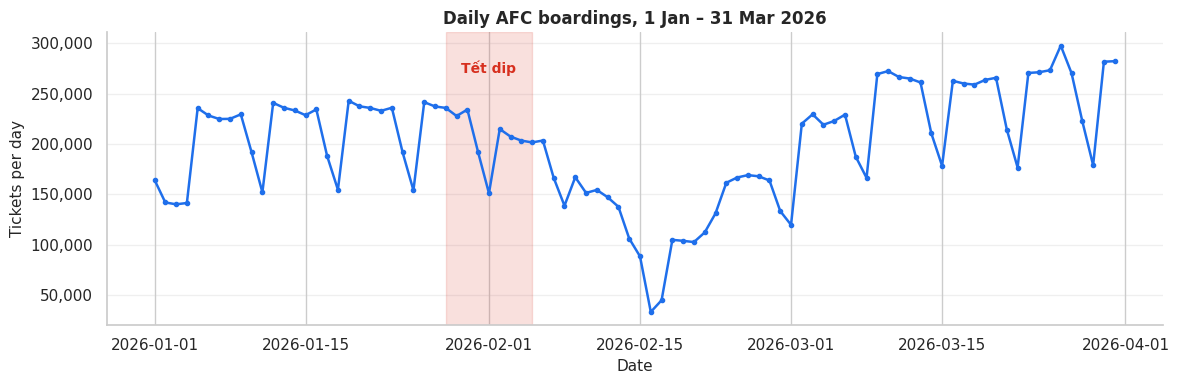

saved figures/eda_daily_boardings.png


In [15]:
daily = db.query("""
    SELECT DATE_TRUNC('day', TO_TIMESTAMP(time_created_ticket))::DATE AS day,
           COUNT(*) AS tickets
    FROM tickets
    GROUP BY day
    ORDER BY day
""").to_pandas()
daily["day"] = pd.to_datetime(daily["day"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily["day"], daily["tickets"],
        color="#1f6feb", lw=1.8, marker="o", markersize=3)
ax.axvspan(TET_START, TET_END, alpha=0.15, color="#d7301f",
           label="Tết window (Jan 28 – Feb 5)")
y_label_pos = daily["tickets"].max() * 0.95
ax.text(TET_START + (TET_END - TET_START) / 2, y_label_pos, "Tết dip",
        ha="center", va="top", fontsize=10, color="#d7301f", fontweight="bold")

ax.set_title("Daily AFC boardings, 1 Jan – 31 Mar 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Tickets per day")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
out = FIG_DIR / "eda_daily_boardings.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out}")


## Figure 2: Hourly boardings by day type (weekday vs weekend)

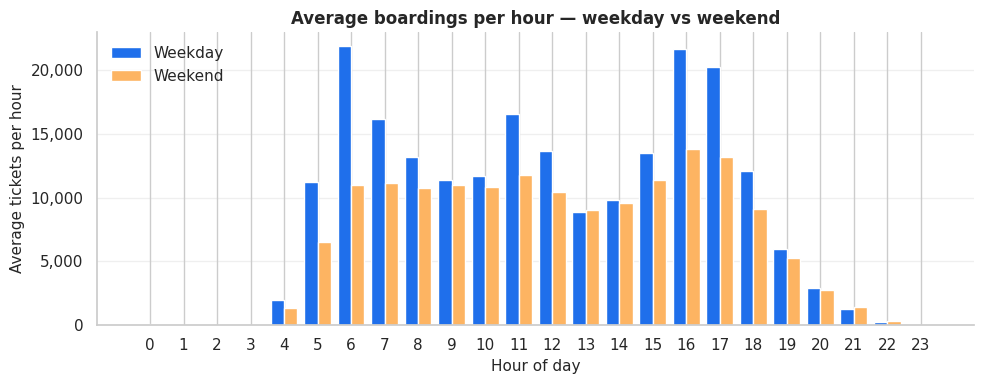

saved figures/eda_hourly_by_daytype.png


In [16]:
hourly = db.query("""
    WITH t AS (
        SELECT TO_TIMESTAMP(time_created_ticket) AS ts FROM tickets
    )
    SELECT
        EXTRACT(HOUR FROM ts)::INT AS hour,
        CASE
            WHEN EXTRACT(DOW FROM ts) IN (0, 6) THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,
        COUNT(*) AS tickets,
        COUNT(DISTINCT DATE_TRUNC('day', ts)) AS n_days
    FROM t
    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_pandas()
hourly["avg_per_hour"] = hourly["tickets"] / hourly["n_days"]

pivot = hourly.pivot(index="hour", columns="day_type",
                     values="avg_per_hour").reindex(range(24))

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.4
x = np.arange(24)
ax.bar(x - width/2, pivot["Weekday"], width=width,
       color="#1f6feb", label="Weekday")
ax.bar(x + width/2, pivot["Weekend"], width=width,
       color="#fdb462", label="Weekend")
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.set_title("Average boardings per hour — weekday vs weekend")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average tickets per hour")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(loc="upper left", frameon=False)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
out = FIG_DIR / "eda_hourly_by_daytype.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out}")


## Figure 3: Fare-class composition by hour of day

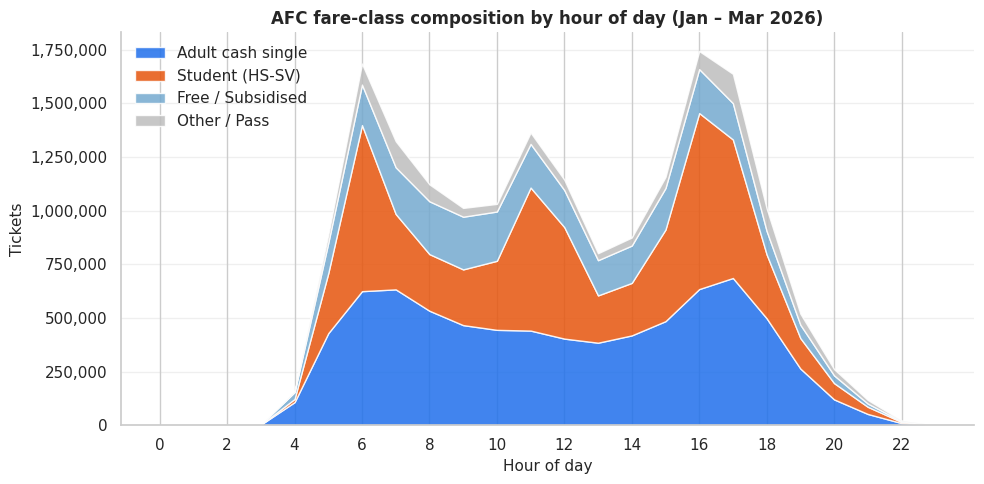

saved figures/eda_fareclass_by_hour.png


In [17]:
fareclass = db.query("""
    SELECT
        EXTRACT(HOUR FROM TO_TIMESTAMP(time_created_ticket))::INT AS hour,
        CASE
            WHEN ticket_type LIKE '%HS-SV%'                 THEN 'Student (HS-SV)'
            WHEN ticket_type ILIKE '%miễn phí%'             THEN 'Free / Subsidised'
            WHEN ticket_type ILIKE '%TM lượt%'              THEN 'Adult cash single'
            ELSE 'Other / Pass'
        END AS fare_group,
        COUNT(*) AS tickets
    FROM tickets
    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_pandas()

order = ["Adult cash single", "Student (HS-SV)", "Free / Subsidised", "Other / Pass"]
pivot = (fareclass
         .pivot(index="hour", columns="fare_group", values="tickets")
         .reindex(range(24))
         .fillna(0)[order])

colors = ["#1f6feb", "#e6550d", "#74a9cf", "#bdbdbd"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(pivot.index, [pivot[c] for c in order],
             labels=order, colors=colors, alpha=0.85)
ax.set_title("AFC fare-class composition by hour of day (Jan – Mar 2026)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Tickets")
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(loc="upper left", frameon=False)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
out = FIG_DIR / "eda_fareclass_by_hour.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out}")


## Figure 4: Route-volume Pareto chart (top 50)

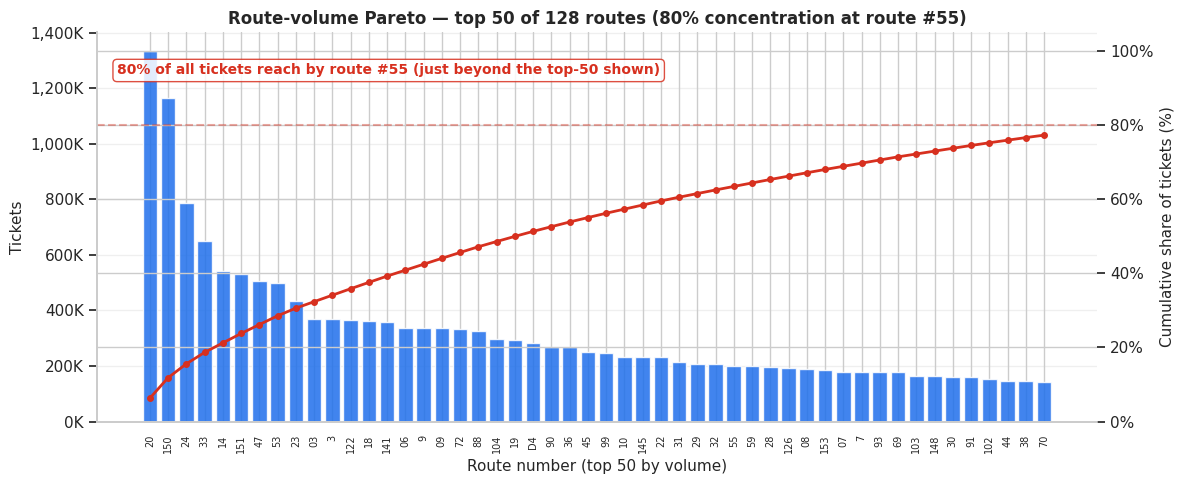

saved figures/eda_route_pareto.png  (80% crossover at route #55, total routes=128)


In [18]:
route_demand = db.query("""
    SELECT r.route_no, COUNT(*) AS tickets
    FROM tickets t
    JOIN ticket_trips tr ON t.trip_id = tr.trip_id
    JOIN ticket_routes r ON tr.route_id = r.route_id
    WHERE t.trip_id IS NOT NULL
    GROUP BY r.route_no
    ORDER BY tickets DESC
""").to_pandas()

total_tickets = route_demand["tickets"].sum()
route_demand["cum_pct"] = 100 * route_demand["tickets"].cumsum() / total_tickets

# Index (1-based) of the first route whose cumulative share crosses 80%
i80 = int((route_demand["cum_pct"] >= 80).idxmax()) + 1
top = route_demand.head(50).copy()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

bars = ax1.bar(range(len(top)), top["tickets"],
               color="#1f6feb", alpha=0.85, label="Tickets per route")
ax1.set_xticks(range(len(top)))
ax1.set_xticklabels(top["route_no"], rotation=90, fontsize=7)
ax1.set_xlabel("Route number (top 50 by volume)")
ax1.set_ylabel("Tickets")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v/1000):,}K"))
ax1.grid(True, axis="y", alpha=0.3)

ax2.plot(range(len(top)), top["cum_pct"], color="#d7301f",
         lw=2, marker="o", markersize=4, label="Cumulative % of all tickets")
ax2.axhline(80, ls="--", color="#d7301f", alpha=0.4)
ax2.set_ylabel("Cumulative share of tickets (%)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_ylim(0, 105)

# Annotate the 80% crossing point if it falls inside the top-50 window
if i80 <= len(top):
    crossing_pct = top["cum_pct"].iloc[i80 - 1]
    ax2.annotate(
        f"80% reached at route #{i80}\n({top['route_no'].iloc[i80-1]})",
        xy=(i80 - 1, crossing_pct),
        xytext=(i80 + 2, 60),
        arrowprops=dict(arrowstyle="->", color="#d7301f", lw=1),
        fontsize=10, color="#d7301f", fontweight="bold",
    )
else:
    ax2.text(0.02, 0.92,
             f"80% of all tickets reach by route #{i80} (just beyond the top-50 shown)",
             transform=ax2.transAxes, ha="left", va="top",
             fontsize=10, color="#d7301f", fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                       edgecolor="#d7301f", alpha=0.85))

ax1.set_title(f"Route-volume Pareto — top 50 of {len(route_demand)} routes "
              f"(80% concentration at route #{i80})")
plt.tight_layout()
out = FIG_DIR / "eda_route_pareto.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out}  (80% crossover at route #{i80}, total routes={len(route_demand)})")


## Figure 5: Payment channel trend over time (cash vs non-cash)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

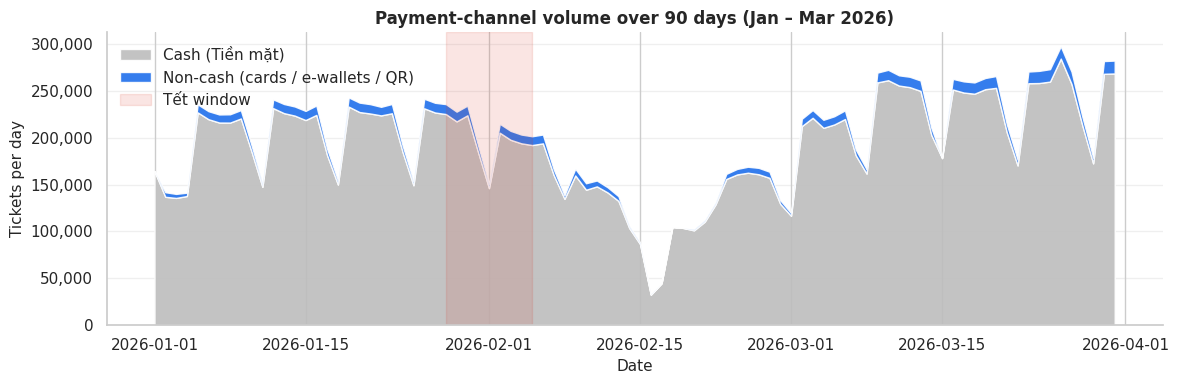

saved figures/eda_payment_trend.png
Overall share — Cash: 96.2%, Non-cash: 3.8%


In [19]:
pay = db.query("""
    SELECT
        DATE_TRUNC('day', TO_TIMESTAMP(t.time_created_ticket))::DATE AS day,
        CASE WHEN p.payment_method = 'Tiền mặt' THEN 'Cash' ELSE 'Non-cash' END AS channel,
        COUNT(*) AS tickets
    FROM tickets t
    JOIN payments p ON t.ticket_id = p.ticket_id
    GROUP BY 1, 2
    ORDER BY 1, 2
""").to_pandas()
pay["day"] = pd.to_datetime(pay["day"])

pivot = (pay
         .pivot(index="day", columns="channel", values="tickets")
         .fillna(0)[["Cash", "Non-cash"]])

fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(pivot.index,
             pivot["Cash"], pivot["Non-cash"],
             labels=["Cash (Tiền mặt)", "Non-cash (cards / e-wallets / QR)"],
             colors=["#bdbdbd", "#1f6feb"], alpha=0.9)
ax.axvspan(TET_START, TET_END, alpha=0.12, color="#d7301f", label="Tết window")
ax.set_title("Payment-channel volume over 90 days (Jan – Mar 2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Tickets per day")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(loc="upper left", frameon=False)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
out = FIG_DIR / "eda_payment_trend.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()

share = pivot.sum() / pivot.sum().sum()
print(f"saved {out}")
print(f"Overall share — Cash: {share['Cash']*100:.1f}%, Non-cash: {share['Non-cash']*100:.1f}%")
